# Random Forest — saved results and team comparison

Read artifacts from `train_random_forest.ipynb`; this notebook does **not** train models or open raw traffic files. By default it loads the newest completed **full six-fold run**, excluding quick tests. Set `RUN_DIR` explicitly to inspect a particular saved experiment. Feature definitions, target, and scoring remain owned by the shared module.

## Completed six-fold run

The saved run uses **all 29 shared features**, a new 300-tree Random Forest per quarter, and the team's training sampling convention. A last-fold quick test was completed first without modifying the team summary. The final July–December 2025 holdout was excluded.

| Measure | Six-fold result |
|---|---:|
| Mean AP onsets | 0.7495 |
| Standard deviation of AP | 0.0088 |
| Worst-quarter AP | 0.7384 |
| Mean Brier score | 0.0230 |
| Onsets caught ≥15 min ahead at 0.5 | 52.6% |
| False-warning episodes per day at 0.5 | 30.05 |
| Wrong-alert hours per day at 0.5 | 4.46 |

AP is a row-level ranking measure on the shared primary population; the caught-onsets measure is episode-level. The alert metrics use the default 0.5 cutoff. Use the saved tradeoff curve before choosing a warning budget. These are development results, not final holdout estimates.

Local artifacts: `src/random_forest/results/random_forest_shared_29_features_full_20261031_200713_030817`. Team comparison files are in `notebooks/results/`. `random_forest_results.ipynb` loads the saved probabilities and models' diagnostics without retraining. The model uses the 29-feature current vector; the recorded transformer uses a historical sequence, so their comparison is between model systems.

The training notebook retains the executed full-run settings (`QUICK_RUN = False`). Set it to `True` before a future smoke test. This static summary describes the saved run and should be updated after rerunning with new settings.


In [1]:
# Resolve repository paths from the root or any notebook subfolder.
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks" / "safeflow_features.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from inside the SafeFlow repository")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))

from pathlib import Path
import sys
PROJECT_DIR = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "notebooks" / "safeflow_features.py").exists() and (p / "data").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start the kernel in the SafeFlow project or a subdirectory")
sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))
import gc
import json
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import safeflow_features as sf
from src.random_forest import random_forest_training as training
LOCAL_DIR = PROJECT_DIR / "src" / "random_forest"
TEAM_RESULTS = PROJECT_DIR / "notebooks" / "results"
pd.set_option("display.width", 160)

In [2]:
RUN_DIR = None
if RUN_DIR is None:
    candidates = []
    for file in (LOCAL_DIR / "results").glob("*/manifest.json"):
        info = json.loads(file.read_text(encoding="utf-8"))
        if info.get("status") == "complete" and not info.get("quick_run"):
            candidates.append(file.parent)
    if not candidates:
        raise FileNotFoundError("No completed full run. Run train_random_forest.ipynb with QUICK_RUN=False first")
    RUN_DIR = sorted(candidates)[-1]
RUN_DIR = training.local_path(RUN_DIR)
manifest = json.loads((RUN_DIR / "manifest.json").read_text(encoding="utf-8"))
if training.sha256_file(sf.__file__) != manifest["shared_code_sha256"]:
    raise RuntimeError("The shared scoring module changed since this run. Restore the recorded version before recomputing metrics.")
if manifest.get("status") != "complete":
    raise ValueError("Selected run is incomplete")
fold_results = pd.read_csv(RUN_DIR / "fold_results.csv").set_index("fold")
files = sorted(RUN_DIR.glob("*/validation_predictions.parquet"))
predictions = pd.concat([pd.read_parquet(file) for file in files], ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)
assert len(files) == len(manifest["completed_fold_names"])
assert not predictions.duplicated(sf.KEY).any()
assert predictions.timestamp.max() < pd.Timestamp(manifest["holdout_start"])
print("Run:", RUN_DIR)
print("Features:", len(manifest["features"]), "Hash:", manifest["feature_sha256"])
print("Parameters:", manifest["model_parameters"])
display(fold_results.round(4))

Run: C:\Erdos\Project\safeflow\src\random_forest\results\random_forest_shared_29_features_full_20261031_200713_030817
Features: 29 Hash: fa4e751633a62111b7fecf0af3d42ccf8eac22bef62cdd81d56f4dda1109cfda
Parameters: {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 10, 'max_samples': 0.25, 'n_jobs': -1, 'random_state': 42}


,"AP, onsets","AP, all",Brier,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets,train_rows,validation_rows,encoded_features,fit_seconds
fold,,,,,,,,,,,,,
2024-01 to 2024-03,0.7458,0.9617,0.0228,0.5821,35.6613,5.6640,0.9090,20.0,1706,822976,479136,46,72.0890
2024-04 to 2024-06,0.7612,0.9607,0.0213,0.5368,29.4603,4.3849,0.9142,20.0,1453,1142237,486864,46,103.0051
2024-07 to 2024-09,0.7428,0.9592,0.0237,0.5064,28.0000,4.1159,0.9176,20.0,1491,1441817,494592,46,136.6644
2024-10 to 2024-12,0.7576,0.9670,0.0245,0.5285,28.8226,4.1586,0.9287,20.0,1546,1716532,479136,46,167.8139
2025-01 to 2025-03,0.7384,0.9653,0.0234,0.5054,29.3934,4.3156,0.9264,20.0,1561,1992536,471408,46,171.6274
2025-04 to 2025-06,0.7508,0.9652,0.0223,0.4954,28.9524,4.1323,0.9276,15.0,1536,2000000,486864,46,199.1818


## 1. Quarterly AP and primary precision–recall curve

The primary population has measured current readings, is not congested now, and has all six future readings measured. Mean per-quarter AP is the team comparison metric. Pooled AP combines all validation predictions and is reported separately; the two need not be identical. The dashed reference is the positive fraction on the scored population, not a fixed universal chance score.

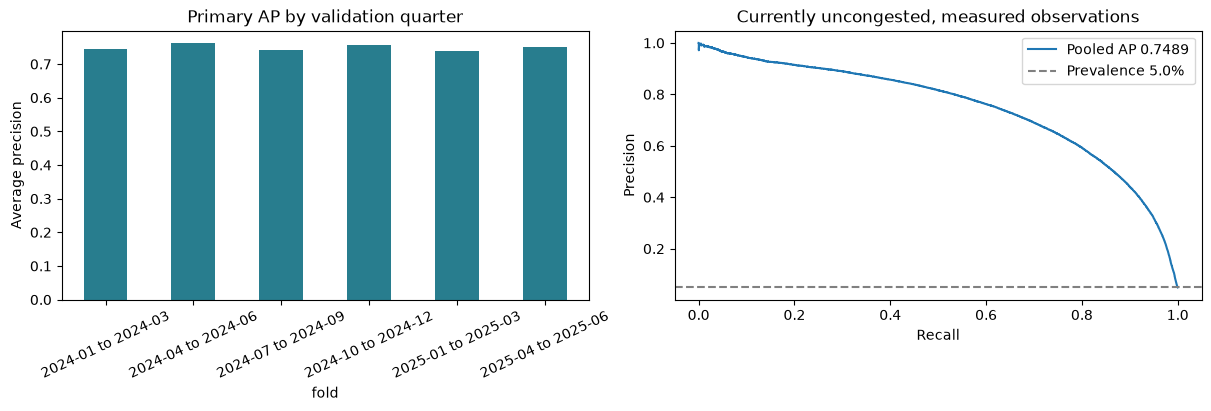

Mean quarterly AP: 0.7494565657591319 Std: 0.008758885027066584
Pooled AP: 0.748868469572236 Scored rows: 1558627 Positive fraction: 0.04951601634002234


In [3]:
from sklearn.metrics import average_precision_score, precision_recall_curve
primary = predictions.y_known & predictions.real & ~predictions.congested_now
rows = predictions.loc[primary]
p, r, _ = precision_recall_curve(rows.y, rows.probability)
pooled_ap = average_precision_score(rows.y, rows.probability)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
fold_results["AP, onsets"].plot.bar(ax=axes[0], color="#287d8e")
axes[0].set(title="Primary AP by validation quarter", ylabel="Average precision")
axes[0].tick_params(axis="x", rotation=25)
axes[1].plot(r, p, label=f"Pooled AP {pooled_ap:.4f}")
axes[1].axhline(rows.y.mean(), color="gray", linestyle="--", label=f"Prevalence {rows.y.mean():.1%}")
axes[1].set(title="Currently uncongested, measured observations", xlabel="Recall", ylabel="Precision")
axes[1].legend()
fig.savefig(RUN_DIR / "primary_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()
print("Mean quarterly AP:", fold_results["AP, onsets"].mean(), "Std:", fold_results["AP, onsets"].std())
print("Pooled AP:", pooled_ap, "Scored rows:", len(rows), "Positive fraction:", rows.y.mean())

## 2. Operational warning tradeoff

Use the shared event definition and alert scoring. The left panel shows onset episodes caught at least 15 minutes ahead versus false-warning episodes per day across the corridor. The right panel shows wrong-alert duration, which can tell a different story than episode counts. These validation curves support choosing an alert budget; they are not holdout estimates. No threshold is selected automatically here.

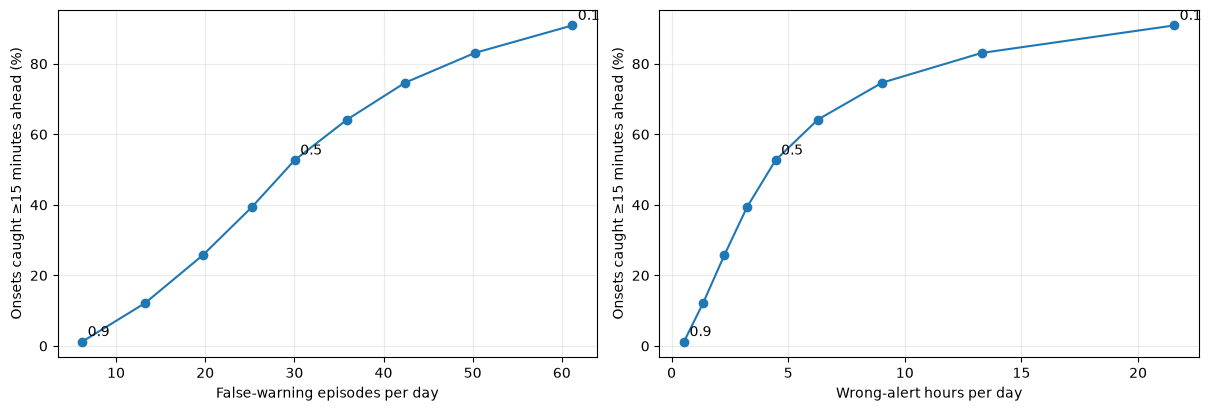

,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
threshold,,,,,,
0.1,0.909,61.171,21.545,0.728,30.0,9293
0.2,0.831,50.245,13.296,0.809,30.0,9293
0.3,0.746,42.424,9.026,0.859,30.0,9293
0.4,0.642,35.915,6.274,0.895,25.0,9293
0.5,0.527,30.035,4.459,0.921,20.0,9293
0.6,0.394,25.245,3.237,0.939,15.0,9293
0.7,0.257,19.717,2.259,0.955,10.0,9293
0.8,0.121,13.240,1.349,0.970,10.0,9293
0.9,0.012,6.197,0.530,0.986,5.0,9293


In [4]:
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 2)
tradeoff = pd.DataFrame([sf.alert_metrics(predictions, predictions.probability.to_numpy(), t) for t in thresholds],
                        index=pd.Index(thresholds, name="threshold"))
tradeoff.to_csv(RUN_DIR / "threshold_tradeoff.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, column, label in zip(axes, ["false alarms / day", "wrong-alert hours / day"],
                             ["False-warning episodes per day", "Wrong-alert hours per day"]):
    ax.plot(tradeoff[column], 100*tradeoff["caught ≥15 min"], marker="o")
    for t in [0.1, 0.5, 0.9]:
        ax.annotate(str(t), (tradeoff.loc[t, column], 100*tradeoff.loc[t, "caught ≥15 min"]), xytext=(4, 4), textcoords="offset points")
    ax.set(xlabel=label, ylabel="Onsets caught ≥15 minutes ahead (%)")
    ax.grid(alpha=0.25)
fig.savefig(RUN_DIR / "warning_tradeoff.png", dpi=160, bbox_inches="tight")
plt.show()
display(tradeoff.round(3))

## 3. Calibration and station coverage

Calibration uses all known future outcomes, while primary AP excludes currently congested stations. Points near the diagonal indicate agreement between predicted probabilities and observed frequencies; sparse bins are omitted. Coverage reports how many measured, currently uncongested validation examples each station contributes. High pooled AP alone does not imply reliable probabilities or uniform station performance.

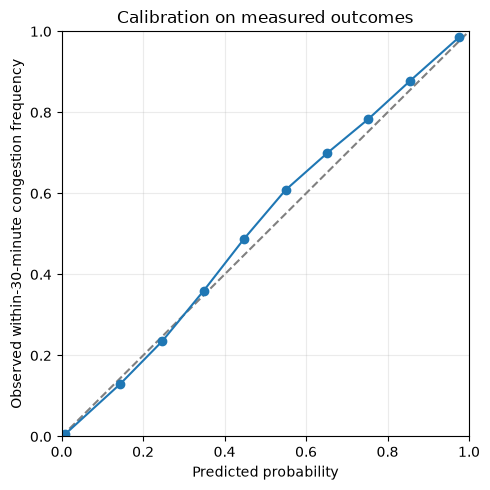

,predictions,known_outcomes,primary_rows
station,,,
1205045,63000,0,0
1205071,63000,28244,27100
1205088,63000,46171,25634
1205135,63000,51741,44199
1205152,63000,56478,56065
1205157,63000,4181,4170
1205165,63000,60046,58348
1205168,63000,20016,15426
1205175,63000,59970,42800


In [5]:
scored = predictions.loc[predictions.y_known]
bins = pd.cut(scored.probability, np.linspace(0, 1, 11), include_lowest=True)
calibration = scored.groupby(bins, observed=True).agg(predicted=("probability", "mean"), actual=("y", "mean"), rows=("y", "size"))
calibration = calibration.loc[calibration.rows >= 100]
calibration.to_csv(RUN_DIR / "calibration.csv")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.plot(calibration.predicted, calibration.actual, marker="o")
ax.set(xlabel="Predicted probability", ylabel="Observed within-30-minute congestion frequency", xlim=(0, 1), ylim=(0, 1), title="Calibration on measured outcomes")
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(RUN_DIR / "calibration.png", dpi=160, bbox_inches="tight")
plt.show()
coverage = predictions.assign(primary=primary).groupby("station").agg(predictions=("y", "size"), known_outcomes=("y_known", "sum"), primary_rows=("primary", "sum"))
coverage.to_csv(RUN_DIR / "station_coverage.csv")
display(coverage)

## 4. Inspect feature use and compare the team table

Impurity-based importance can divide credit arbitrarily among correlated variables and favor predictors with more split opportunities. Use it to inspect the fitted model, not to establish causal contributions or independently validate the shared feature selection.

The team table retains the feature count. The prior boosted-tree row uses 16 features; the transformer row uses 29. Models with different feature contracts are not paired architecture-only comparisons. Check the saved manifests before drawing conclusions. This notebook does not modify other models' results.

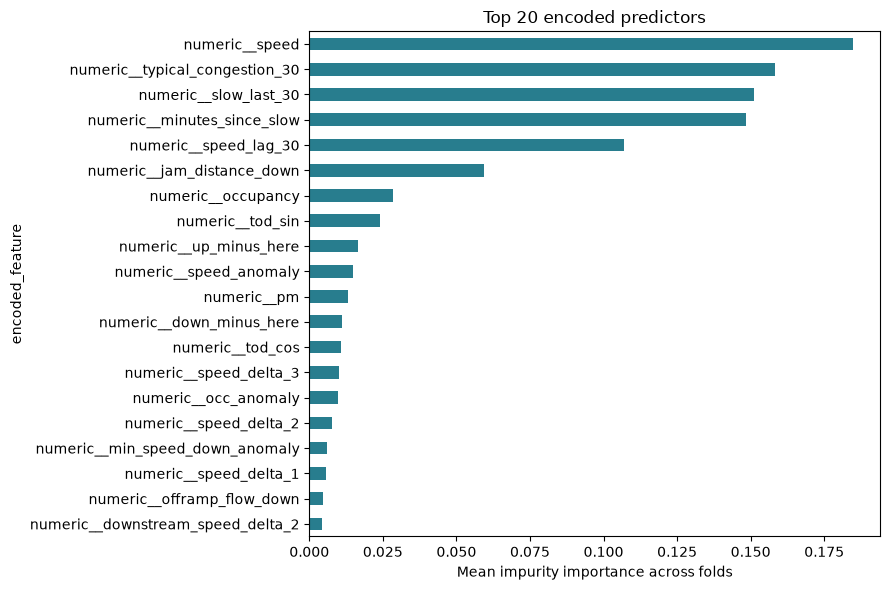

,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
model,,,,,,,,,
transformer_shared_plus_agreed_features,2026-10-31,29,0.7625,0.0168,0.7317,0.0223,0.6633,30.4317,5.5437
random_forest_shared_29_features,2026-10-31,29,0.7495,0.0088,0.7384,0.0230,0.5258,30.0483,4.4619
boosted_trees,2026-10-29,16,0.7494,0.0109,0.7381,0.0231,0.6251,31.1901,5.3615


Rows with 29 logical features:


,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
model,,,,,,,,,
transformer_shared_plus_agreed_features,2026-10-31,29,0.7625,0.0168,0.7317,0.0223,0.6633,30.4317,5.5437
random_forest_shared_29_features,2026-10-31,29,0.7495,0.0088,0.7384,0.0230,0.5258,30.0483,4.4619


Saved analysis figures/tables: C:\Erdos\Project\safeflow\src\random_forest\results\random_forest_shared_29_features_full_20261031_200713_030817


In [6]:
importance = pd.concat([pd.read_csv(file).assign(fold=file.parent.name) for file in RUN_DIR.glob("*/feature_importance.csv")], ignore_index=True)
mean_importance = (importance.groupby("encoded_feature").impurity_importance.sum() / len(fold_results)).sort_values(ascending=False)
mean_importance.to_csv(RUN_DIR / "mean_feature_importance.csv")
fig, ax = plt.subplots(figsize=(9, 6))
mean_importance.head(20).sort_values().plot.barh(ax=ax, color="#287d8e")
ax.set(xlabel="Mean impurity importance across folds", title="Top 20 encoded predictors")
plt.tight_layout()
fig.savefig(RUN_DIR / "feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()
if (TEAM_RESULTS / "summary.csv").exists():
    team = pd.read_csv(TEAM_RESULTS / "summary.csv")
    display(team.set_index("model").round(4))
    print("Rows with 29 logical features:")
    display(team.loc[team.features.eq(29)].set_index("model").round(4))
print("Saved analysis figures/tables:", RUN_DIR)

## 5. Recorded transformer reference by quarter

Compare matching quarters with the saved 29-feature transformer run. The transformer uses a historical sequence while the forest uses the current 29-feature vector, so this is a model-system comparison. Check training sample counts and feature contracts before interpretation. Paired AP differences are descriptive; no significance claim or holdout conclusion is made.

,"AP, onsets_forest",train_rows_forest,"AP, onsets_transformer",train_rows_transformer,AP_forest_minus_transformer
fold,,,,,
2024-01 to 2024-03,0.7458,822976,0.7317,822976,0.0141
2024-04 to 2024-06,0.7612,1142237,0.7709,1142237,-0.0097
2024-07 to 2024-09,0.7428,1441817,0.7613,1441817,-0.0185
2024-10 to 2024-12,0.7576,1716532,0.7785,1716532,-0.0209
2025-01 to 2025-03,0.7384,1992536,0.7592,1992536,-0.0208
2025-04 to 2025-06,0.7508,2000000,0.7732,2000000,-0.0224


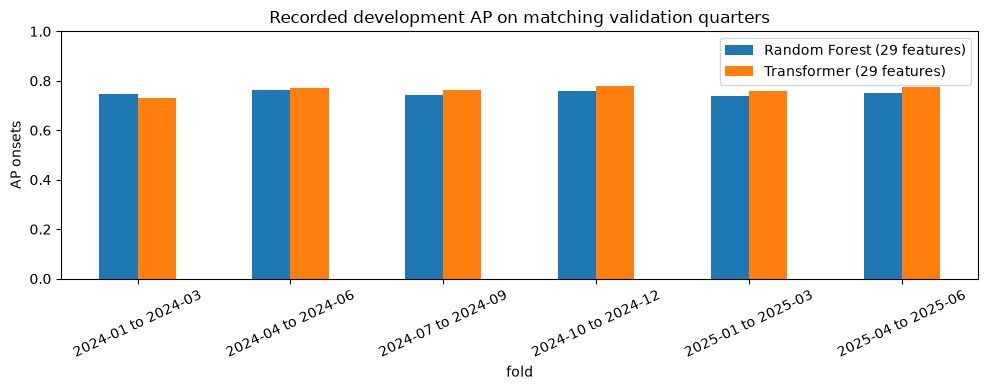

In [7]:
transformer_name = "transformer_shared_plus_agreed_features"
reference_file = TEAM_RESULTS / f"{transformer_name}_folds.csv"
if reference_file.exists():
    reference = pd.read_csv(reference_file).set_index("fold")
    paired = fold_results[["AP, onsets", "train_rows"]].join(
        reference[["AP, onsets", "train_rows"]], how="inner", lsuffix="_forest", rsuffix="_transformer")
    paired["AP_forest_minus_transformer"] = paired["AP, onsets_forest"] - paired["AP, onsets_transformer"]
    print("Matching training endpoint counts:", paired.train_rows_forest.eq(paired.train_rows_transformer).all())
    print("Quarters compared:", len(paired))
    print("Mean paired AP difference:", paired.AP_forest_minus_transformer.mean())
    display(paired.round(4))
    paired.to_csv(RUN_DIR / "paired_transformer_comparison.csv")
    fig, ax = plt.subplots(figsize=(10, 4))
    paired[["AP, onsets_forest", "AP, onsets_transformer"]].rename(
        columns={"AP, onsets_forest": "Random Forest (29 features)", "AP, onsets_transformer": "Transformer (29 features)"}).plot.bar(ax=ax)
    ax.set(ylabel="AP onsets", title="Recorded development AP on matching validation quarters", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    fig.savefig(RUN_DIR / "paired_model_average_precision.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No saved transformer fold CSV available for paired comparison")